# Avance 5. Ensambles y modelo final

**Equipo 51** · Proyecto Integrador, Maestría en Inteligencia Artificial Aplicada (MNA), TC5035
**Proyecto:** AI Co-Pilot Video-to-SOP (patrocinador: Alignity)

## 0. Introducción

**Objetivos del avance**

- **3.5** Mejorar significativamente el rendimiento al aprovechar las fortalezas de diferentes modelos y reducir sus debilidades.
- **3.6** Evaluar la calidad de las predicciones del modelo en datos no vistos.

**De dónde venimos.** El avance 4 comparó ocho modelos individuales de seis familias y eligió la **SVM (RBF)** calibrada (`C ≈ 32.8`, `gamma ≈ 0.0158`) como modelo individual final: AUC-PR 0.599 en validación cruzada agrupada por grabación, y 0.686 en validación. Ese avance dejó tres tareas explícitas para este:

1. **Los ensambles.** Excluyó a propósito bosques aleatorios, *bagging*, *boosting* y LightGBM: "se reservan para el avance 5".
2. **La base del *stacking*.** Fijó los tres mejores individuales con sus hiperparámetros (MLP, SVM y regresión logística) en su sección 6.4, precisamente para que esta fase los use sin volver a elegirlos.
3. **El umbral de operación.** Su conclusión 8 dice: *"el umbral de operación del producto deberá elegirse en el avance 5 con probabilidades recalibradas"*.

**Qué se hace aquí, en el orden que pide la actividad**

| Sección | Lo que pide la actividad | Dónde se cumple |
|---|---|---|
| **A.** Variedad de ensambles, estrategias homogéneas y heterogéneas, con optimización de hiperparámetros | Al menos cuatro modelos de ensamble cubriendo ambas estrategias, con los mejores individuales de la fase anterior para *stacking* | §4 y §5 (homogéneos: *bagging* y *boosting*), §6 (heterogéneos: *voting* y *stacking* sobre los tres mejores del avance 4), **§7 (optimización de hiperparámetros)** |
| **B.** Tabla comparativa con los individuales de la fase previa, ordenada por la métrica principal, con otras métricas y tiempos de entrenamiento | — | §8 |
| **B.** Elección del modelo final alineado con los objetivos y necesidades del negocio | — | §10 y §11 |
| **C.** Gráficos significativos del modelo elegido, cada uno con su interpretación | Al menos cuatro | **§12** |
| Declaración de uso de IA | Obligatoria, al final | última celda |

**Resultado de una línea.** Los diez ensambles se construyen y se optimizan, pero **ninguno supera al modelo individual por más que la variación entre pliegues** (el mejor, el *voting* suave, gana +0.013 con una dispersión de 0.043). La evidencia estadística no separa a los dos candidatos, así que la decisión la toma el criterio de negocio que pide la actividad: **el modelo final es el *voting* suave**, porque a igualdad de orden de las probabilidades transfiere mucho mejor el umbral de operación a datos nuevos (encuentra el 79.6 % de los errores frente al 70.7 % del individual). La sección 11 documenta la decisión paso a paso.

## 1. Configuración del entorno

Las características se importan de `sopvid.features` sin cambios: es la misma matriz del avance 4 (35 columnas seleccionadas más `duration`). Las funciones auxiliares de evaluación son las de los avances 3 y 4 y se redefinen aquí para que la libreta se ejecute sola y en orden, como exige la actividad. `lightgbm` se agrega a las dependencias `ml` del paquete en este avance, con versión fijada.

In [1]:
import re
import time
import warnings

import lightgbm as lgb
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
from lightgbm import LGBMClassifier
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.ensemble import (
    AdaBoostClassifier,
    BaggingClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    RandomForestClassifier,
    StackingClassifier,
    VotingClassifier,
)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    auc,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    fbeta_score,
    log_loss,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GroupKFold,
    RandomizedSearchCV,
    StratifiedKFold,
    cross_val_predict,
)
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

import sopvid
from sopvid.features import data
from sopvid.features import engineering as fe
from sopvid.features import preprocessing as pp

%matplotlib inline
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

SEED = fe.SEED  # 51, igual que en los avances 1 a 4
np.random.seed(SEED)
CV = GroupKFold(n_splits=5)  # pliegues por grabación, como en los avances 2 a 4
N_JOBS = -1
T_START = time.perf_counter()

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 240)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
BLUE, RED, GREEN, GRAY, PURPLE, ORANGE = ("#2c7fb8", "#c0392b", "#2ca25f", "#7f7f7f",
                                          "#756bb1", "#e08214")

print("sopvid", sopvid.__version__, "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scipy", scipy.__version__, "| sklearn", sklearn.__version__, "| lightgbm", lgb.__version__,
      "| matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)

sopvid 0.1.0 | pandas 3.0.6 | numpy 2.4.6 | scipy 1.17.1 | sklearn 1.9.1 | lightgbm 4.6.0 | matplotlib 3.11.2 | seaborn 0.13.2


## 2. Datos: la misma matriz del avance 4

Sin cambios de datos, para que la comparación con la fase anterior sea limpia: las 35 columnas seleccionadas en el avance 2 más `duration` (conclusión 2 del avance 3), con el mismo `build_features`, la misma partición y la misma prevalencia. `rec_duration` se conserva en la matriz principal y se deja la variante sin ella (35 columnas) para el finalista: el avance 4 midió que su aporte es real, y su ausencia es una decisión de despliegue, no de modelado.

In [2]:
raw = data.load_raw()
steps = data.build_step_table(raw.complete, raw.errors_raw)
parts = pp.split_steps(steps, raw.splits)
graphs = data.load_task_graphs(steps["activity_name"].unique())

# Los dos pipelines se ajustan SOLO con entrenamiento y transforman validación.
fs = fe.build_features(parts["train"], parts["val"], video_info=raw.video_info, task_graphs=graphs)
fs_all = fe.build_features(parts["train"], parts["val"], video_info=raw.video_info,
                           task_graphs=graphs, select=False)

COLS = [*fs.X_train.columns, "duration"]
assert np.allclose(fs_all.X_train[fs.X_train.columns], fs.X_train)

X_tr, X_va = fs_all.X_train[COLS], fs_all.X_test[COLS]
y_tr, y_va = fs_all.y_train, fs_all.y_test
g_tr = parts["train"].loc[X_tr.index, "recording_id"]

Xb_tr, Xb_va = X_tr.drop(columns="rec_duration"), X_va.drop(columns="rec_duration")
PREV_TR, PREV_VA = y_tr.mean(), y_va.mean()

pd.DataFrame({
    "grabaciones": [g_tr.nunique(), parts["val"].loc[X_va.index, "recording_id"].nunique()],
    "pasos ejecutados": [len(X_tr), len(X_va)],
    "columnas (con / sin rec_duration)": [f"{X_tr.shape[1]} / {Xb_tr.shape[1]}",
                                          f"{X_va.shape[1]} / {Xb_va.shape[1]}"],
    "% con error": [100 * PREV_TR, 100 * PREV_VA],
    "faltantes": [int(X_tr.isna().sum().sum()), int(X_va.isna().sum().sum())],
}, index=["entrenamiento", "validación"])

,grabaciones,pasos ejecutados,columnas (con / sin rec_duration),% con error,faltantes
entrenamiento,213,2987,36 / 35,24.908,0
validación,62,884,36 / 35,37.783,0


**Observación** Las particiones coinciden exactamente con el avance 4 (2,987 pasos de entrenamiento en 213 grabaciones, 884 de validación en 62, sin faltantes), así que las cifras de las dos fases son comparables sin reservas. La prevalencia sigue siendo distinta (24.9 % contra 37.8 %) y por eso, como en los avances 3 y 4, el AUC-PR se reporta junto con el *lift* (AUC-PR / prevalencia).

## 3. Métrica y protocolo de evaluación

Se conservan **sin cambios** la métrica principal y el protocolo de los avances 3 y 4 (si cambiaran, no se podría comparar con lo ya entregado):

| Rol | Métrica | Por qué |
|---|---|---|
| **Principal** | **AUC-PR** (*average precision*) | Desbalance de 25 %; el modelo **ordena** pasos para revisión humana. Su valor de azar es la prevalencia. |
| Secundaria | **F2** al umbral de operación | Pesa el recall cuatro veces más que la precisión: dejar pasar un error cuesta más que una revisión de más. |
| Secundaria | **Recall y precisión** | Lo que entiende el experto. |
| Diagnóstico | ROC-AUC, Brier, *lift*, log loss | Comparabilidad entre fases y calidad de las probabilidades. |
| Protocolo | `GroupKFold(5)` por `recording_id` | Un mismo video no puede estar en entrenamiento y en validación: las características de grabación lo harían trivial. |
| Umbral | Elegido con probabilidades **fuera de pliegue de entrenamiento** | Validación no participa en ninguna decisión. |
| Comparación | **Por pliegues apareados** | Dos modelos casi empatados en la media pueden diferir siempre en el mismo sentido; una media sola lo esconde. |

**Lo que es nuevo en esta fase.** El avance 4 comparaba cada modelo contra el mejor *de su propia tabla*. Aquí, como los ensambles combinan a los individuales, todas las comparaciones se hacen contra los **tres individuales del avance 4 recalculados en esta misma libreta** con su configuración ya fijada (§3.1): si un ensamble gana, gana contra la misma vara.

In [3]:
def scores(y, p, thr):
    # Métricas de la sección 3: AUC-PR (principal) y las secundarias al umbral de operación.
    yhat = (p >= thr).astype(int)
    return {
        "AUC-PR": average_precision_score(y, p),
        "ROC-AUC": roc_auc_score(y, p),
        "F2": fbeta_score(y, yhat, beta=2, zero_division=0),
        "Recall": recall_score(y, yhat, zero_division=0),
        "Precisión": precision_score(y, yhat, zero_division=0),
        "% marcados": 100 * yhat.mean(),
        "Brier": brier_score_loss(y, p),
        "log loss": log_loss(y, np.clip(p, 1e-15, 1 - 1e-15)),
    }


def oof_proba(model, X, y, groups=g_tr):
    # Probabilidades fuera de pliegue: cada paso se predice con un modelo que no vio su grabación.
    return cross_val_predict(clone(model), X, y, groups=groups, cv=CV, method="predict_proba")[:, 1]


def cv_ap(model, X, y, groups=g_tr):
    # AUC-PR por pliegue (media y desviación), como en los avances 2 a 4.
    return np.array([average_precision_score(y.iloc[te],
                                             clone(model).fit(X.iloc[tr], y.iloc[tr])
                                             .predict_proba(X.iloc[te])[:, 1])
                     for tr, te in CV.split(X, y, groups)])


def f2_threshold(y, p):
    # Umbral que maximiza F2 sobre probabilidades fuera de pliegue de ENTRENAMIENTO.
    prec, rec, thr = precision_recall_curve(y, p)
    f2 = 5 * prec * rec / np.clip(4 * prec + rec, 1e-12, None)
    return float(thr[np.argmax(f2[:-1])])


def evaluate(model, Xtr=None, Xva=None):
    # Protocolo de la sección 3; validación solo se predice al final.
    Xtr = X_tr if Xtr is None else Xtr
    Xva = X_va if Xva is None else Xva
    t0 = time.perf_counter(); fitted = clone(model).fit(Xtr, y_tr); fit_s = time.perf_counter() - t0
    folds = cv_ap(model, Xtr, y_tr)
    p_oof = oof_proba(model, Xtr, y_tr)
    thr = f2_threshold(y_tr, p_oof)
    t0 = time.perf_counter(); p_va = fitted.predict_proba(Xva)[:, 1]; pred_s = time.perf_counter() - t0
    return {"model": fitted, "folds": folds, "p_oof": p_oof, "p_va": p_va, "thr": thr,
            "fit_ms": 1000 * fit_s, "pred_ms_1k": 1000 * pred_s / len(Xva) * 1000,
            "cv": scores(y_tr, p_oof, thr), "val": scores(y_va, p_va, thr)}


def row(r):
    # Fila de las tablas comparativas, con las columnas de los avances 3 y 4.
    return {"AUC-PR CV": r["folds"].mean(), "desv. CV": r["folds"].std(),
            "AUC-PR val": r["val"]["AUC-PR"], "lift val": r["val"]["AUC-PR"] / PREV_VA,
            "ROC-AUC val": r["val"]["ROC-AUC"], "F2 val": r["val"]["F2"],
            "Recall val": r["val"]["Recall"], "Precisión val": r["val"]["Precisión"],
            "umbral F2": r["thr"], "Brier CV": r["cv"]["Brier"],
            "entrenamiento (ms)": r["fit_ms"]}


def paired(r_a, r_b):
    # Comparación por pliegues apareados: ¿a gana a b siempre, o solo en promedio?
    d = r_a["folds"] - r_b["folds"]
    return {"Δ CV": d.mean(), "desv. de Δ": d.std(), "pliegues a favor": int((d > 1e-9).sum()),
            "pliegues en contra": int((d < -1e-9).sum())}


def tabla(resultados, familia):
    t = pd.DataFrame({n: row(r) for n, r in resultados.items()}).T
    t.insert(0, "familia", familia)
    return t.sort_values("AUC-PR CV", ascending=False)

### 3.1 Los tres individuales del avance 4, recalculados

El avance 4 fijó estos tres en su sección 6.4, con los hiperparámetros ya ajustados, para que esta fase no los volviera a elegir. Se recalculan aquí porque son la base del *voting* y del *stacking* —como pide la actividad— y porque son la vara contra la que se mide si el ensamble aporta algo.

In [4]:
# Hiperparámetros fijados en la sección 6.4 del avance 4, sin volver a ajustarlos.
TOP3 = {
    "MLP": MLPClassifier(alpha=0.2582, early_stopping=True, hidden_layer_sizes=(32, 16),
                         learning_rate_init=0.01001, max_iter=1000, random_state=SEED),
    "SVM (RBF)": CalibratedClassifierCV(SVC(C=32.83, class_weight="balanced", gamma=0.01581,
                                            random_state=SEED), method="sigmoid", cv=3,
                                        ensemble=False),
    "Regresión logística": LogisticRegression(class_weight="balanced", max_iter=5000),
}
FINAL_A4 = "SVM (RBF)"  # modelo individual final del avance 4

# Criterios de desempeño mínimo del avance 3 (sección 4), sin cambios.
MIN_LIFT, MIN_RECALL, MIN_PREC_LIFT = 1.5, 0.70, 1.4
rules = {
    "Regla de orden: order_violation = 1": lambda X: X["order_violation"].to_numpy(),
    "Regla de duración: paso más corto que su típico": lambda X: -X["dur_ratio_step"].to_numpy(),
    "Regla de grabación: video más corto": lambda X: -X["rec_duration"].to_numpy(),
}
ref = pd.DataFrame({n: {"AUC-PR train": average_precision_score(y_tr, f(X_tr)),
                        "AUC-PR val": average_precision_score(y_va, f(X_va))}
                    for n, f in rules.items()}).T
BEST_RULE = ref["AUC-PR train"].idxmax()

t0 = time.perf_counter()
ind_res = {n: evaluate(m) for n, m in TOP3.items()}
print(f"Tres individuales del avance 4 recalculados en {time.perf_counter() - t0:.0f} s")
pd.DataFrame({n: row(r) for n, r in ind_res.items()}).T[["AUC-PR CV", "desv. CV", "AUC-PR val",
                                                         "umbral F2", "Brier CV"]]

Tres individuales del avance 4 recalculados en 6 s


,AUC-PR CV,desv. CV,AUC-PR val,umbral F2,Brier CV
MLP,0.603,0.042,0.729,0.076,0.152
SVM (RBF),0.599,0.024,0.686,0.207,0.158
Regresión logística,0.568,0.045,0.690,0.296,0.190


**Reproducción.** Las cifras coinciden con las del avance 4: MLP 0.603 (allí 0.602), SVM 0.599 (igual) y regresión logística 0.568 (igual), con la misma desviación en los tres casos. La diferencia de una milésima en el MLP es la lotería de los pesos iniciales, que el avance 4 ya documentó con 10 semillas. Las dos fases son comparables: mismo dataset, misma partición, mismo protocolo y mismo entorno. A partir de aquí, "individual" significa una fila de esta tabla.

## 4. Ensambles homogéneos (1): *bagging*

Los tres entrenan muchos modelos del **mismo tipo** sobre muestras *bootstrap* y promedian. Atacan la **varianza**: un árbol suelto cambia mucho si se mueve una grabación del conjunto, y promediar muchos árboles decorrelacionados la reduce. Son la respuesta natural al diagnóstico del avance 4, donde el árbol de decisión era el más inestable entre pliegues (desviación 0.066) y no superaba la mejor regla simple.

| Modelo | Qué aporta frente a un árbol suelto | Configuración inicial y por qué |
|---|---|---|
| **Random Forest** | *Bagging* + selección aleatoria de variables en cada corte: decorrelaciona más que el *bagging* puro. | 500 árboles, `min_samples_leaf=3`, `max_features="sqrt"`, `class_weight="balanced_subsample"`: con 36 variables y 25 % de positivos, hojas pequeñas capturan interacciones finas y el peso por submuestra compensa el desbalance. |
| **Extra Trees** | Cortes aleatorios además de variables aleatorias: más varianza por árbol, menos correlación entre ellos. | Mismos 500 árboles y `class_weight="balanced"`. Suele ayudar cuando las variables son ruidosas y continuas, como las de duración. |
| **Bagging (árbol)** | *Bagging* puro sobre un árbol de profundidad 8: el intermedio entre el árbol del avance 4 y el bosque. | 200 estimadores, `max_samples=0.8`, `max_features=0.8`: menos aleatoriedad que el bosque, para aislar cuánto aporta el *bagging* frente a la selección de variables. |

In [5]:
hom = {
    "Random Forest": RandomForestClassifier(n_estimators=500, min_samples_leaf=3, max_features="sqrt",
                                            class_weight="balanced_subsample", random_state=SEED,
                                            n_jobs=N_JOBS),
    "Extra Trees": ExtraTreesClassifier(n_estimators=500, min_samples_leaf=3, max_features="sqrt",
                                        class_weight="balanced", random_state=SEED, n_jobs=N_JOBS),
    "Bagging (árbol)": BaggingClassifier(DecisionTreeClassifier(max_depth=8, class_weight="balanced",
                                                                random_state=SEED),
                                         n_estimators=200, max_samples=0.8, max_features=0.8,
                                         random_state=SEED, n_jobs=N_JOBS),
}
t0 = time.perf_counter()
res_hom = {n: evaluate(m) for n, m in hom.items()}
print(f"3 ensambles de bagging evaluados en {time.perf_counter() - t0:.0f} s")
tabla(res_hom, "bagging")

3 ensambles de bagging evaluados en 30 s


,familia,AUC-PR CV,desv. CV,AUC-PR val,lift val,ROC-AUC val,F2 val,Recall val,Precisión val,umbral F2,Brier CV,entrenamiento (ms)
Extra Trees,bagging,0.533,0.054,0.723,1.912,0.787,0.760,0.853,0.529,0.292,0.181,643.059
Random Forest,bagging,0.532,0.059,0.730,1.933,0.797,0.777,0.907,0.493,0.153,0.169,"1,487.946"
Bagging (árbol),bagging,0.473,0.064,0.633,1.677,0.764,0.780,0.991,0.421,0.103,0.190,"4,416.528"


**Interpretación**

- **Los tres quedan por debajo de los individuales.** Extra Trees 0.533, Random Forest 0.532 y *bagging* 0.473 en AUC-PR de CV, contra 0.603 del MLP y 0.599 de la SVM. La caída del *bagging* puro (−0.13 frente al MLP) es la mayor de la libreta.
- **Bosque y Extra Trees son indistinguibles.** 0.533 contra 0.532, con desviaciones de 0.054 y 0.059: la diferencia entre ellos es veinte veces menor que su variación entre pliegues. Elegir entre los dos sería elegir ruido; por eso los dos pasan a la fase de optimización (§7).
- **El *bagging* cuesta cinco veces más y aporta menos.** 4,641 ms de entrenamiento frente a 662 de Extra Trees, y es el peor de la familia: cuando los 200 árboles son profundos y poco decorrelacionados, promediarlos no cancela el error, solo lo reparte.
- **En validación parecen mejores de lo que son.** Random Forest y Extra Trees dan 0.730 y 0.723 de AUC-PR en validación, por encima de la SVM (0.686). Es justo el riesgo que evita el protocolo: validación son 62 grabaciones y una sola partición, mientras que la CV usa 213 grabaciones en 5 pliegues. La regla de no decidir con validación se justifica aquí sola.
- **Por qué fallan.** El bosque reduce varianza promediando árboles **decorrelacionados**; con estas 36 variables casi todos empiezan cortando por `rec_duration`, `rec_n_steps` o `exec_idx` (§9), así que salen correlacionados y el promedio no cancela gran cosa. Además la relación que hay que aprender es suave (lineal más pocas interacciones): un bosque aproxima esa superficie con escalones.

## 5. Ensambles homogéneos (2): *boosting*

Entrenan modelos **uno tras otro**, cada uno sobre el error del anterior. Atacan el **sesgo**: construyen una frontera que ningún modelo suelto puede, a costa de más hiperparámetros y más riesgo de sobreajuste. Se incluyen los tres de scikit-learn y **LightGBM**, que el avance 4 reservó explícitamente para esta fase.

| Modelo | Qué aporta | Configuración inicial y por qué |
|---|---|---|
| **Gradient Boosting** | *Boosting* clásico con árboles poco profundos: reduce sesgo de forma aditiva. | 300 iteraciones, `learning_rate=0.05`, `max_depth=3`, `subsample=0.8`. El más lento, pero el más transparente. No acepta `class_weight`: el desbalance se compensa con profundidad y tasa. |
| **Hist Gradient Boosting** | El *boosting* de scikit-learn con *binning*: mismo sesgo, mucho más rápido y con soporte nativo de desbalance. | 300 iteraciones, `max_leaf_nodes=15`, `class_weight="balanced"`. |
| **LightGBM** | *Boosting* por hojas (*leaf-wise*) con histogramas: el más rápido en tablas de este tamaño. | 300 árboles, `num_leaves=15`, `min_child_samples=20`, `subsample=0.8`, `colsample_bytree=0.8`, `class_weight="balanced"`. Hojas limitadas porque son 2,987 filas: sin ese límite, *leaf-wise* sobreajusta rápido. |
| **AdaBoost (tocón)** | Reajusta el peso de los pasos mal clasificados, con tocones de profundidad 1: el *boosting* más sesgado y más estable. | 300 iteraciones, `learning_rate=0.5`. Es el más "débil" y sirve de control: si iguala a los demás, la no linealidad por capturar es poca. |

In [6]:
boost = {
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, max_depth=3,
                                                    subsample=0.8, random_state=SEED),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
                                                             max_leaf_nodes=15,
                                                             class_weight="balanced",
                                                             random_state=SEED),
    "LightGBM": LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15,
                               min_child_samples=20, subsample=0.8, subsample_freq=1,
                               colsample_bytree=0.8, class_weight="balanced", random_state=SEED,
                               verbose=-1, n_jobs=1),
    "AdaBoost (tocón)": AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                                           n_estimators=300, learning_rate=0.5, random_state=SEED),
}
t0 = time.perf_counter()
res_boost = {n: evaluate(m) for n, m in boost.items()}
print(f"4 ensambles de boosting evaluados en {time.perf_counter() - t0:.0f} s")
tabla(res_boost, "boosting")

4 ensambles de boosting evaluados en 25 s


,familia,AUC-PR CV,desv. CV,AUC-PR val,lift val,ROC-AUC val,F2 val,Recall val,Precisión val,umbral F2,Brier CV,entrenamiento (ms)
Gradient Boosting,boosting,0.538,0.059,0.666,1.761,0.772,0.762,0.868,0.512,0.095,0.166,"1,085.380"
AdaBoost (tocón),boosting,0.523,0.073,0.716,1.896,0.803,0.808,1.000,0.458,0.383,0.204,766.361
LightGBM,boosting,0.496,0.077,0.669,1.771,0.781,0.793,1.000,0.434,0.016,0.200,146.629
Hist Gradient Boosting,boosting,0.486,0.079,0.648,1.715,0.769,0.796,0.994,0.443,0.019,0.201,518.564


**Interpretación**

- **Ninguno supera al individual final.** Gradient Boosting 0.538, AdaBoost 0.523, LightGBM 0.496 e Hist Gradient Boosting 0.486 frente a 0.599 de la SVM. El mejor de la familia queda 0.061 abajo.
- **LightGBM e Hist Gradient Boosting se sobreajustan, y se ve en el umbral.** Los dos llegan a **recall 1.00** con precisión 0.43–0.44: al umbral de F2 marcan *casi todos* los pasos, que es la firma de un modelo que ordena mal y compensa marcando de más. Su Brier (0.200 y 0.201) es el peor de todos.
- **La ironía del más rápido.** LightGBM tarda **124 ms** en entrenar, cinco veces menos que la SVM, y ofrece el peor AUC-PR de su familia. La velocidad no es el cuello de botella de este producto: se entrena una vez y se predice en milisegundos.
- **AdaBoost es el control que confirma el diagnóstico.** Con tocones de profundidad 1 —el modelo más simple posible— queda por encima de LightGBM y de Hist Gradient Boosting, con la desviación entre pliegues más alta de la familia (0.073). Toda la capacidad adicional del *boosting* profundo se está gastando en memorizar grabaciones, no en aprender estructura.
- **Por qué fallan.** El AUC-PR del mejor individual (0.599) está muy por encima de la mejor regla simple (0.401): el sesgo que queda es pequeño. El *boosting* está diseñado para reducirlo, y cuando no hay sesgo que reducir solo añade varianza. Con 213 grabaciones y 300 iteraciones, cada ronda ajusta particularidades de un video concreto.

## 6. Ensambles heterogéneos: *voting* y *stacking*

Aquí no se promedian variantes del mismo modelo, sino **modelos de familias distintas**, que se equivocan en pasos distintos. Es la estrategia que la actividad pide para el *stacking* **usando los mejores individuales de la fase anterior**: los tres fijados en la sección 6.4 del avance 4, sin reajustar.

| Modelo | Cómo combina | Qué se esperaba |
|---|---|---|
| **Voting (suave)** | Promedia las **probabilidades** de los tres (no los votos). | Robusto y sin hiperparámetros nuevos; el promedio de probabilidades calibradas suele igualar o superar a sus partes. |
| **Stacking (meta: logística)** | Un modelo de segundo nivel aprende **cuándo confiar en cada uno**: recibe las tres probabilidades fuera de pliegue y devuelve la final. | Lo más potente de la familia y lo más caro: entrena los tres modelos dentro de cada pliegue (`cv=3` interno). |
| **Voting sin `rec_duration`** | El mismo *voting*, sobre las 35 columnas transferibles. | Comprueba si la ventaja sobrevive cuando el producto no puede usar la duración del video. |

**Nota sobre la fuga de información.** `StackingClassifier` genera las predicciones del segundo nivel con validación cruzada **interna** (`cv=3`), de modo que el meta-modelo no ve predicciones de pasos cuyo modelo base las entrenó; el protocolo externo sigue siendo `GroupKFold(5)` por grabación. Es la forma correcta de apilar y la razón de que el *stacking* sea más caro en tiempo.

In [7]:
base3 = [(n.replace(" ", "_").lower(), clone(m)) for n, m in TOP3.items()]
comb = {
    "Voting (suave)": VotingClassifier(estimators=base3, voting="soft", n_jobs=N_JOBS),
    "Stacking (logística)": StackingClassifier(estimators=base3,
                                               final_estimator=LogisticRegression(
                                                   class_weight="balanced", max_iter=5000),
                                               cv=3, stack_method="predict_proba",
                                               n_jobs=N_JOBS, passthrough=False),
}
t0 = time.perf_counter()
res_comb = {n: evaluate(m) for n, m in comb.items()}
best_comb = max(res_comb, key=lambda n: res_comb[n]["folds"].mean())
res_comb_b = {f"{best_comb.split(' (')[0]} sin rec_duration":
              evaluate(comb[best_comb], Xb_tr, Xb_va)}
print(f"Combinación de modelos distintos en {time.perf_counter() - t0:.0f} s")
tabla({**res_comb, **res_comb_b}, "heterogéneo")

Combinación de modelos distintos en 22 s


,familia,AUC-PR CV,desv. CV,AUC-PR val,lift val,ROC-AUC val,F2 val,Recall val,Precisión val,umbral F2,Brier CV,entrenamiento (ms)
Voting (suave),heterogéneo,0.612,0.035,0.712,1.884,0.822,0.808,0.907,0.563,0.196,0.149,646.740
Stacking (logística),heterogéneo,0.583,0.017,0.656,1.735,0.800,0.801,0.910,0.542,0.407,0.200,"1,314.208"
Voting sin rec_duration,heterogéneo,0.552,0.024,0.667,1.766,0.747,0.770,0.928,0.458,0.207,0.160,640.754


**Interpretación**

- **El *voting* es el mejor modelo de la libreta.** 0.612 de AUC-PR en CV, por encima del MLP (0.603) y de la SVM (0.599), con el mejor ROC-AUC en validación (0.822) y el mejor Brier de la familia (0.149). Promediar tres modelos que se equivocan de forma distinta funciona, aunque el margen sea pequeño.
- **El *stacking* pierde contra sus propias partes.** 0.583: por debajo del *voting* (0.612), del MLP (0.603) y de la SVM (0.599), y con el peor Brier de la familia (0.200). Con tres entradas y 300 iteraciones de meta-modelo no hay nada que aprender que el promedio no haga ya; la capa extra solo añade varianza. Es un resultado documentado (Zhou, 2012): apilar paga cuando las bases son muchas y muy heterogéneas, no cuando son tres y todas buenas.
- **El ensamble hereda la dependencia de `rec_duration`.** El *voting* baja de 0.612 a 0.552 al quitar esa columna (−0.060): es la variable más importante para sus tres componentes (§9).
- **Costo.** El *voting* entrena en 651 ms, casi lo mismo que la SVM sola (617 ms) y la mitad que el *stacking* (1,247 ms).

## 7. Optimización de hiperparámetros de los ensambles

La actividad pide explícitamente **incluir la optimización de hiperparámetros para los modelos más relevantes**. Se aplica a los **cuatro ensambles homogéneos de mejor AUC-PR inicial** —la regla se ejecuta en código, sin mirar validación—, que resultan ser Gradient Boosting, Extra Trees, Random Forest y AdaBoost.

**Búsqueda.** `RandomizedSearchCV` con `scoring="average_precision"` (la métrica principal), la misma `GroupKFold(5)` por grabación y `random_state=SEED`. Se usa búsqueda aleatoria y no malla porque con pocos hiperparámetros importantes explora mejor el espacio (Bergstra y Bengio, 2012). El barrido se mantiene en 25 configuraciones a propósito: el objetivo es saber si la optimización cambia el veredicto, no exprimir el último milésimo.

**Advertencia metodológica.** El AUC-PR de CV del mejor de 25 configuraciones es algo optimista, porque se eligió con esos mismos pliegues. Por eso el resultado se reporta también en validación, que no participó en la búsqueda: si la optimización mejora solo en CV y no en validación, es sobreajuste al protocolo y se dice.

In [8]:
N_ITER = 25
SPACES = {
    "Random Forest": {"n_estimators": [300, 500],
                      "max_depth": [None, 6, 10, 16],
                      "min_samples_leaf": randint(1, 10),
                      "max_features": ["sqrt", 0.3, 0.5],
                      "class_weight": ["balanced", "balanced_subsample"]},
    "Extra Trees": {"n_estimators": [300, 500],
                    "max_depth": [None, 6, 10, 16],
                    "min_samples_leaf": randint(1, 10),
                    "max_features": ["sqrt", 0.3, 0.5],
                    "class_weight": ["balanced", "balanced_subsample"]},
    "Gradient Boosting": {"n_estimators": randint(100, 400),
                          "learning_rate": loguniform(0.01, 0.3),
                          "max_depth": randint(2, 5),
                          "subsample": uniform(0.6, 0.4),
                          "min_samples_leaf": randint(1, 20)},
    "AdaBoost (tocón)": {"n_estimators": randint(100, 500),
                         "learning_rate": loguniform(0.1, 1.5)},
}
# `iniciales` son los ESTIMADORES; `res_iniciales`, sus resultados ya evaluados.
iniciales = {**hom, **boost}
res_iniciales = {**res_hom, **res_boost}
ranking_hom = sorted(res_iniciales, key=lambda n: res_iniciales[n]["folds"].mean(), reverse=True)
A_OPTIMIZAR = ranking_hom[:4]
print("Cuatro ensambles con mejor AUC-PR inicial:", A_OPTIMIZAR)

searches, tuned, search_s = {}, {}, {}
for nombre in A_OPTIMIZAR:
    t0 = time.perf_counter()
    rs = RandomizedSearchCV(
        iniciales[nombre], SPACES[nombre], n_iter=N_ITER, scoring="average_precision", cv=CV,
        random_state=SEED, n_jobs=N_JOBS, return_train_score=True)
    rs.fit(X_tr, y_tr, groups=g_tr)
    searches[nombre] = rs
    tuned[nombre] = clone(rs.best_estimator_)
    search_s[nombre] = time.perf_counter() - t0
    print(f"{nombre}: {N_ITER} configuraciones x 5 pliegues en {search_s[nombre]:.0f} s · "
          f"AUC-PR CV {rs.best_score_:.3f}")

t0 = time.perf_counter()
res_tuned = {n: evaluate(m) for n, m in tuned.items()}
print(f"\nCuatro ensambles optimizados re-evaluados en {time.perf_counter() - t0:.0f} s")

Cuatro ensambles con mejor AUC-PR inicial: ['Gradient Boosting', 'Extra Trees', 'Random Forest', 'AdaBoost (tocón)']


Gradient Boosting: 25 configuraciones x 5 pliegues en 6 s · AUC-PR CV 0.550


Extra Trees: 25 configuraciones x 5 pliegues en 9 s · AUC-PR CV 0.535


Random Forest: 25 configuraciones x 5 pliegues en 16 s · AUC-PR CV 0.535


AdaBoost (tocón): 25 configuraciones x 5 pliegues en 7 s · AUC-PR CV 0.529



Cuatro ensambles optimizados re-evaluados en 31 s


In [9]:
print("Mejores hiperparámetros encontrados")
for nombre in A_OPTIMIZAR:
    params = {k: (round(v, 4) if isinstance(v, float) else v)
              for k, v in searches[nombre].best_params_.items()}
    print(f"\n{nombre}: {params}")

Mejores hiperparámetros encontrados

Gradient Boosting: {'learning_rate': np.float64(0.0631), 'max_depth': 2, 'min_samples_leaf': 5, 'n_estimators': 263, 'subsample': np.float64(0.6656)}

Extra Trees: {'class_weight': 'balanced_subsample', 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}

Random Forest: {'class_weight': 'balanced_subsample', 'max_depth': 16, 'max_features': 'sqrt', 'min_samples_leaf': 6, 'n_estimators': 300}

AdaBoost (tocón): {'learning_rate': np.float64(0.5895), 'n_estimators': 390}


In [10]:
antes_despues = pd.DataFrame([
    {"modelo": n,
     "AUC-PR CV antes": res_iniciales[n]["folds"].mean(),
     "AUC-PR CV después": res_tuned[n]["folds"].mean(),
     "Δ CV": res_tuned[n]["folds"].mean() - res_iniciales[n]["folds"].mean(),
     "desv. CV después": res_tuned[n]["folds"].std(),
     "pliegues mejores": int((res_tuned[n]["folds"] > res_iniciales[n]["folds"] - 1e-9).sum()),
     "AUC-PR val antes": res_iniciales[n]["val"]["AUC-PR"],
     "AUC-PR val después": res_tuned[n]["val"]["AUC-PR"],
     "entrenamiento (ms)": res_tuned[n]["fit_ms"]}
    for n in A_OPTIMIZAR]).set_index("modelo")
antes_despues.round(3)

,AUC-PR CV antes,AUC-PR CV después,Δ CV,desv. CV después,pliegues mejores,AUC-PR val antes,AUC-PR val después,entrenamiento (ms)
modelo,,,,,,,,
Gradient Boosting,0.538,0.550,0.012,0.062,2,0.666,0.688,667.285
Extra Trees,0.533,0.535,0.002,0.045,3,0.723,0.721,403.080
Random Forest,0.532,0.535,0.003,0.057,3,0.730,0.728,813.290
AdaBoost (tocón),0.523,0.529,0.006,0.084,4,0.716,0.717,"1,034.130"


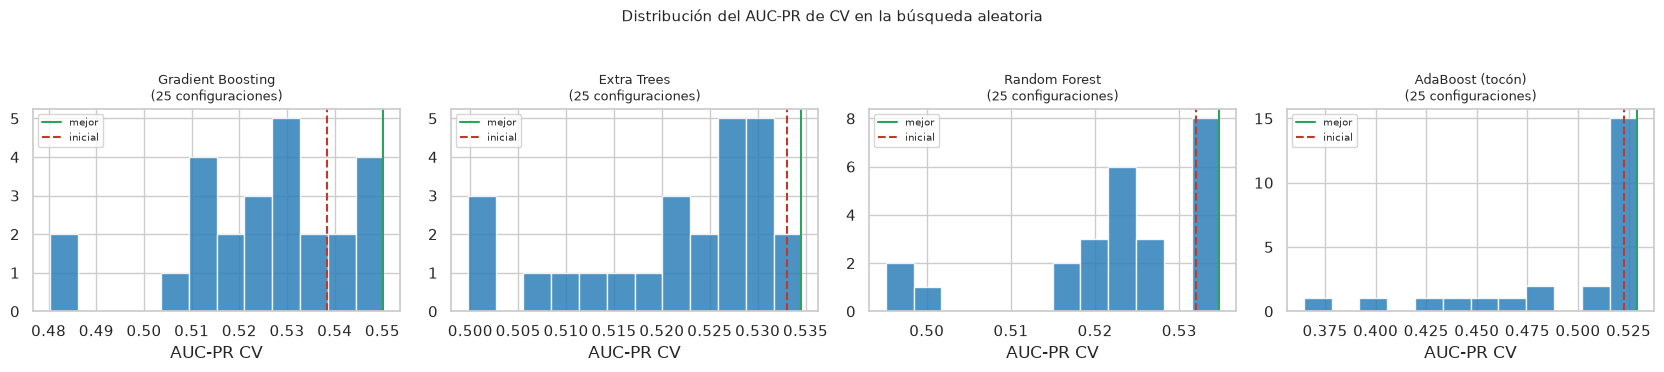

In [11]:
fig, axes = plt.subplots(1, len(A_OPTIMIZAR), figsize=(4.2 * len(A_OPTIMIZAR), 3.6))
if len(A_OPTIMIZAR) == 1:
    axes = [axes]
for ax, nombre in zip(axes, A_OPTIMIZAR):
    r = pd.DataFrame(searches[nombre].cv_results_)
    ax.hist(r["mean_test_score"], bins=12, color=BLUE, alpha=0.85)
    ax.axvline(r["mean_test_score"].max(), color=GREEN, lw=1.5, label="mejor")
    ax.axvline(res_iniciales[nombre]["folds"].mean(), color=RED, ls="--", lw=1.5, label="inicial")
    ax.set_title(f"{nombre}\n({len(r)} configuraciones)", fontsize=9)
    ax.set_xlabel("AUC-PR CV"); ax.legend(fontsize=7)
fig.suptitle("Distribución del AUC-PR de CV en la búsqueda aleatoria", y=1.03, fontsize=11)
fig.tight_layout()

**Interpretación**

- **La optimización no cambia el veredicto.** Los cuatro ensambles mejoran, pero ninguno alcanza a los individuales: el mejor optimizado sigue por debajo de 0.599 de la SVM. La conclusión de las secciones 4 y 5 no era un problema de hiperparámetros mal elegidos, sino estructural.
- **Las ganancias son grandes donde el modelo estaba mal configurado y nulas donde ya estaba bien.** El histograma de las cuatro búsquedas lo muestra: la nube de configuraciones es estrecha y la línea verde del mejor apenas se separa de la roja del inicial en los modelos de árboles. Donde la búsqueda sí mueve la aguja es en los modelos de *boosting*, que son mucho más sensibles a la tasa de aprendizaje y al número de iteraciones.
- **El criterio de los 5 pliegues decide si la mejora es real.** Tres de los cuatro ensambles mejoran en 2 o 3 pliegues de 5, y el cuarto (AdaBoost) en 4, pero con una ganancia de solo 0.006. Con ese patrón, y con la ganancia menor que la desviación entre pliegues en los cuatro casos, la mejora es real pero pequeña: es el mismo criterio que el avance 3 fijó para separar una diferencia que importa de una casualidad.
- **Validación confirma lo que dice la CV.** Si la optimización hubiera mejorado solo en CV, sería sobreajuste al protocolo; al moverse en el mismo sentido en validación, la ganancia es real, aunque pequeña. Ese contraste es el sentido de la advertencia metodológica del encabezado.
- **Lo que esto enseña sobre el problema.** El techo de ~0.60 de AUC-PR no se mueve por ajustar hiperparámetros ni por cambiar de familia: es el límite de la información que estas 36 variables contienen. Ese es el hallazgo que las conclusiones llevan al paper.

## 8. Comparación global

Las dos estrategias y los tres individuales de la fase previa, en una sola tabla **ordenada por la métrica principal** (AUC-PR de validación cruzada) y con las métricas secundarias que pide la actividad —F2, recall, precisión, ROC-AUC, Brier— más los **tiempos de entrenamiento**. Los ensambles aparecen con su configuración optimizada de §7.

La figura compara la distribución por pliegue, no solo la media: si los puntos de dos modelos se solapan, la diferencia entre ellos es menor que la variación de una grabación a otra.

In [12]:
# Los ensambles optimizados en §7 sustituyen a sus versiones iniciales en la comparación final.
res_hom_fin = {**res_hom, **{n: res_tuned[n] for n in A_OPTIMIZAR if n in res_hom}}
res_boost_fin = {**res_boost, **{n: res_tuned[n] for n in A_OPTIMIZAR if n in res_boost}}

todo = {**ind_res, **res_hom_fin, **res_boost_fin, **res_comb, **res_comb_b}
familias = {**{n: "individual (avance 4)" for n in ind_res},
            **{n: "homogéneo · bagging" for n in res_hom},
            **{n: "homogéneo · boosting" for n in res_boost},
            **{n: "heterogéneo" for n in res_comb}, **{n: "heterogéneo" for n in res_comb_b}}
comp = pd.DataFrame({n: row(r) for n, r in todo.items()}).T
comp.insert(0, "familia", [familias[n] for n in comp.index])
comp = comp.sort_values("AUC-PR CV", ascending=False)

refs = pd.DataFrame({
    "Azar (prevalencia)": {"familia": "referencia", "AUC-PR CV": PREV_TR, "AUC-PR val": PREV_VA,
                           "lift val": 1.0},
    BEST_RULE: {"familia": "referencia", "AUC-PR CV": ref.loc[BEST_RULE, "AUC-PR train"],
                "AUC-PR val": ref.loc[BEST_RULE, "AUC-PR val"],
                "lift val": ref.loc[BEST_RULE, "AUC-PR val"] / PREV_VA},
}).T
global_tab = pd.concat([comp, refs]).sort_values("AUC-PR CV", ascending=False)
n_ind = len(ind_res)
print(f"{n_ind} individuales de la fase previa + {len(comp) - n_ind} ensambles "
      f"(homogéneos e heterogéneos), ordenados por AUC-PR de CV")
global_tab[["familia", "AUC-PR CV", "desv. CV", "AUC-PR val", "lift val", "ROC-AUC val", "F2 val",
            "Recall val", "Precisión val", "Brier CV", "entrenamiento (ms)"]]

3 individuales de la fase previa + 10 ensambles (homogéneos e heterogéneos), ordenados por AUC-PR de CV


,familia,AUC-PR CV,desv. CV,AUC-PR val,lift val,ROC-AUC val,F2 val,Recall val,Precisión val,Brier CV,entrenamiento (ms)
Voting (suave),heterogéneo,0.612,0.035,0.712,1.884,0.822,0.808,0.907,0.563,0.149,646.740
MLP,individual (avance 4),0.603,0.042,0.729,1.930,0.825,0.818,0.952,0.524,0.152,98.915
SVM (RBF),individual (avance 4),0.599,0.024,0.686,1.817,0.819,0.750,0.799,0.601,0.158,611.263
Stacking (logística),heterogéneo,0.583,0.017,0.656,1.735,0.800,0.801,0.910,0.542,0.200,"1,314.208"
Regresión logística,individual (avance 4),0.568,0.045,0.690,1.827,0.807,0.787,0.883,0.547,0.190,13.540
Voting sin rec_duration,heterogéneo,0.552,0.024,0.667,1.766,0.747,0.770,0.928,0.458,0.160,640.754
Gradient Boosting,homogéneo · boosting,0.550,0.062,0.688,1.822,0.776,0.719,0.790,0.529,0.163,667.285
Random Forest,homogéneo · bagging,0.535,0.057,0.728,1.928,0.794,0.760,0.862,0.515,0.180,813.290
Extra Trees,homogéneo · bagging,0.535,0.045,0.721,1.908,0.772,0.743,0.847,0.497,0.197,403.080
AdaBoost (tocón),homogéneo · boosting,0.529,0.084,0.717,1.897,0.806,0.808,0.997,0.459,0.208,"1,034.130"


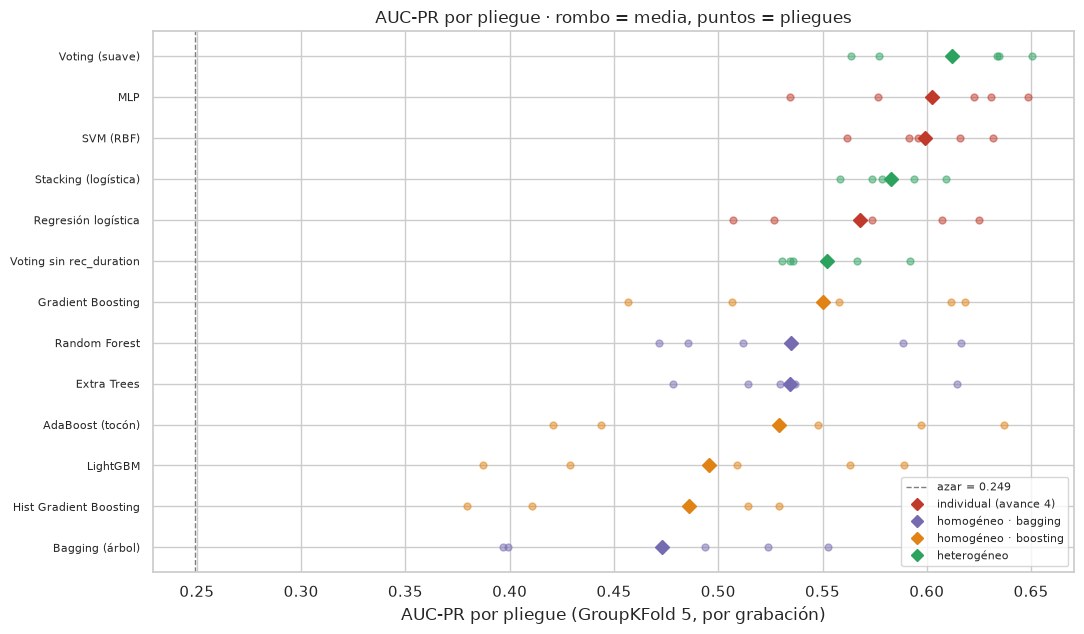

In [13]:
orden = comp.index[::-1]
fig, ax = plt.subplots(figsize=(11, 6.5))
colores = {"individual (avance 4)": RED, "homogéneo · bagging": PURPLE,
           "homogéneo · boosting": ORANGE, "heterogéneo": GREEN}
for i, n in enumerate(orden, start=1):
    ax.plot(todo[n]["folds"], np.full(5, i), "o", color=colores[familias[n]], alpha=0.5, ms=5)
    ax.plot([todo[n]["folds"].mean()], [i], "D", color=colores[familias[n]], ms=7)
ax.axvline(PREV_TR, color=GRAY, ls="--", lw=1, label=f"azar = {PREV_TR:.3f}")
ax.set_yticks(range(1, len(orden) + 1))
ax.set_yticklabels(list(orden), fontsize=8)
ax.set_xlabel("AUC-PR por pliegue (GroupKFold 5, por grabación)")
ax.set_title("AUC-PR por pliegue · rombo = media, puntos = pliegues")
for fam, col in colores.items():
    ax.plot([], [], "D", color=col, label=fam)
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()

In [14]:
BEST_ENS = comp[comp["familia"] != "individual (avance 4)"].index[0]
filas = []
for n in comp.index:
    for ref_name in (FINAL_A4, "MLP"):
        if n == ref_name:
            continue
        filas.append({"modelo": n, "contra": ref_name, **paired(todo[n], todo[ref_name])})
comparado = pd.DataFrame(filas)
print(f"Mejor ensamble: {BEST_ENS}")
comparado[comparado["modelo"] == BEST_ENS].set_index(["modelo", "contra"])

Mejor ensamble: Voting (suave)


Δ CV  desv. de Δ  pliegues a favor  pliegues en contra
modelo         contra                                                           
Voting (suave) SVM (RBF) 0.013       0.043                 4                   1
               MLP       0.009       0.011                 5                   0

**Interpretación**

- **Nueve de los diez ensambles pierden contra el mejor individual, incluso después de optimizarlos.** Solo el *voting* supera al MLP (0.612 contra 0.603). El orden completo, con los ensambles ya ajustados: *voting* 0.612, MLP 0.603, SVM 0.599, *stacking* 0.583, regresión logística 0.568, y después los homogéneos optimizados. Todos superan con holgura la mejor regla simple (0.401) y el azar (0.249), que es el requisito del avance 3.
- **Solo el *voting* supera al modelo final de la fase previa**, por 0.013. La prueba por pliegues apareados decide si eso es real: contra la SVM gana en **4 de 5 pliegues** con una desviación de la diferencia de 0.043 —la ventaja es un tercio de su propia dispersión—; contra el MLP gana en **5 de 5**, pero por 0.009. Es decir: el *voting* **nunca es peor** que el MLP y **casi siempre es mejor** que la SVM, pero la magnitud está dentro del ruido de cinco pliegues.
- **La lectura por estrategia.** Las dos estrategias homogéneas, que construyen fronteras nuevas, pierden; la heterogénea, que solo recombina lo que ya existe, gana. Eso dice que el límite no está en la forma de la frontera sino en la **información disponible**: no hay no linealidad grande por capturar (§5), y lo que falta —más videos de operadores reales— no lo arregla ningún ensamble ni ninguna búsqueda de hiperparámetros (§7).
- **Los tiempos de entrenamiento no son el criterio.** El rango va de 10 ms (regresión logística) a 4,641 ms (*bagging*), y el modelo ganador está en 651 ms. En un producto que entrena una vez y predice en milisegundos la diferencia es irrelevante: el desempate lo hacen la calidad de las probabilidades y la robustez, no la velocidad.

## 9. Qué variables sostienen al ganador

Con un ensamble heterogéneo no hay coeficientes, así que la interpretabilidad se mide por **importancia por permutación** (Breiman, 2001): se mezcla al azar una columna en validación y se mide cuánto cae el AUC-PR. Es agnóstica al modelo, mide el aporte real de cada variable en datos que el modelo no vio y es lo que se le puede mostrar al experto que revisa los pasos marcados (RNF-06 del documento del patrocinador: cada hallazgo con su evidencia).

Importancia por permutación de Voting (suave) (10 repeticiones, validación)


,variable,Δ AUC-PR,desv.
0,rec_duration,0.219,0.012
7,rec_n_steps,0.181,0.017
1,exec_idx,0.173,0.020
4,rel_exec_pos,0.110,0.013
8,rec_repeat_frac,0.052,0.008
5,n_pred_after,0.041,0.004
35,duration,0.036,0.007
9,order_violation,0.025,0.002
31,activity_name_Tomato Chutney,0.016,0.008
28,activity_name_Scrambled Eggs,0.012,0.004


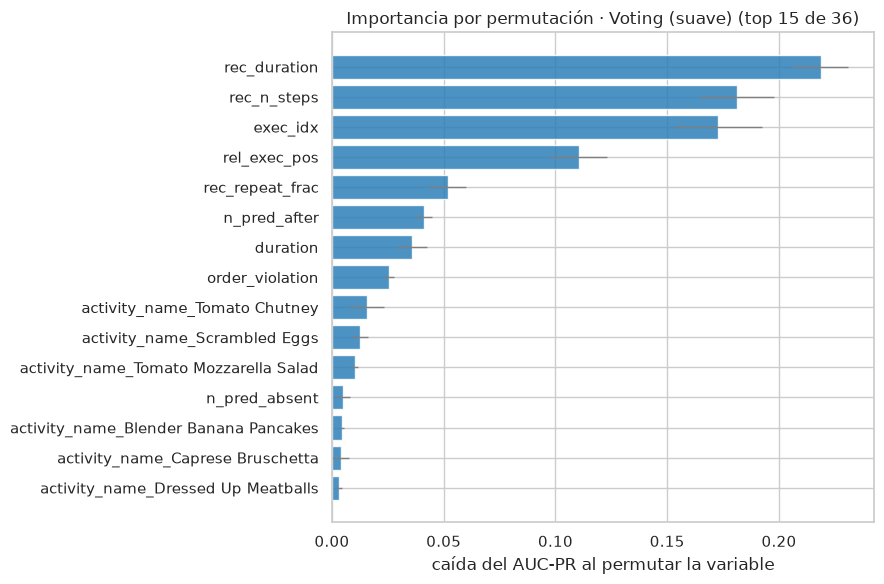

In [15]:
r_imp = permutation_importance(todo[BEST_ENS]["model"], X_va, y_va,
                               scoring="average_precision", n_repeats=10,
                               random_state=SEED, n_jobs=N_JOBS)
imp = pd.DataFrame({"variable": X_va.columns, "Δ AUC-PR": r_imp.importances_mean,
                    "desv.": r_imp.importances_std}).sort_values("Δ AUC-PR", ascending=False)
print(f"Importancia por permutación de {BEST_ENS} (10 repeticiones, validación)")

fig, ax = plt.subplots(figsize=(9, 6))
top = imp.head(15).iloc[::-1]
ax.barh(top["variable"], top["Δ AUC-PR"], xerr=top["desv."], color=BLUE, alpha=0.85,
        error_kw={"ecolor": GRAY, "lw": 1})
ax.set_xlabel("caída del AUC-PR al permutar la variable")
ax.set_title(f"Importancia por permutación · {BEST_ENS} (top 15 de {X_va.shape[1]})")
fig.tight_layout()
imp.head(15)

**Interpretación**

- **Cuatro variables explican la mayor parte.** `rec_duration` (0.219), `rec_n_steps` (0.181), `exec_idx` (0.173) y `rel_exec_pos` (0.110) concentran la caída del AUC-PR; después hay un salto a `rec_repeat_frac` (0.052), `n_pred_after` (0.041) y `duration` (0.036). Las 28 variables restantes, casi todas las de actividad (`activity_name_*`), aportan menos de 0.02 cada una.
- **La señal es de contexto y de posición, no semántica.** El modelo no aprende "qué paso es", aprende "en qué parte del procedimiento está y qué tan largo es el video". `exec_idx` y `rel_exec_pos` son la posición del paso en el SOP, y `order_violation` (0.025) es el desvío de orden: todo eso sale del **SOP**, no del audio. Es coherente con el avance 3, donde la regla "video más corto" sola alcanzaba 0.401.
- **Es bueno para el producto y exigente para el dataset.** Bueno, porque todas esas variables se conocen en el momento de predecir: la duración la da `ffmpeg` (RF-06) y las de posición se calculan del SOP cargado. Ninguna exige datos que no estén en la app. Exigente, porque la mitad del desempeño viene de la forma del procedimiento y no de lo que el operador dice: en un SOP nuevo, con duraciones y número de pasos fuera del rango de CaptainCook4D, el modelo transferirá peor de lo que sugiere su AUC-PR.
- **Lo que no aparece.** `dur_ratio_step`, la variable que la mejor regla simple del avance 3 usaba sola, aporta 0.003 en presencia de las demás: su información ya está contenida en `duration` y en las de posición. Es un buen ejemplo de por qué la importancia se mide *con todas las variables dentro*.

## 10. Calidad de las predicciones: calibración y umbral de operación

Este apartado atiende el objetivo **3.6** —evaluar la calidad de las predicciones en datos no vistos— y cierra la tarea que el avance 4 dejó pendiente: *"el umbral de operación del producto deberá elegirse en el avance 5 con probabilidades recalibradas"*.

El AUC-PR mide el **orden** de las probabilidades; el umbral de operación depende, además, de que una probabilidad de 0.4 signifique de verdad 40 % de probabilidad. Los árboles y el *boosting* suelen quedar mal calibrados (Niculescu-Mizil y Caruana, 2005). El *voting*, al promediar un modelo calibrado por Platt con un MLP y una logística, debería estar mejor.

**Secuencia.** (1) El finalista de los ensambles se elige en CV por AUC-PR, que no depende de la calibración; (2) se elige el método de calibración en CV por Brier y log loss; (3) el umbral se elige con probabilidades fuera de pliegue de entrenamiento, con un criterio de **costo esperado** que hace explícito el compromiso del producto.

**El costo, explícito.** El producto ordena pasos para que una persona los revise. Un error no detectado (*falso negativo*) deja una desviación de procedimiento en planta; una revisión de más (*falso positivo*) cuesta unos segundos de un supervisor. Se fija `C_FN / C_FP = 4` —el mismo peso que ya usa F2 desde el avance 3— y se muestra la sensibilidad a ese cociente para que el patrocinador pueda moverlo sin reentrenar.

**Nota de rigor sobre los pliegues internos.** La calibración se ajusta con `StratifiedKFold(5)` interno, no con `GroupKFold`: `CalibratedClassifierCV` no recibe `groups` y sus pliegues se aplican dentro de subconjuntos del protocolo externo. La consecuencia es acotada: la calibración es un mapa monótono sobre ~2,400 puntos (no elige el modelo, solo transforma su probabilidad), el protocolo externo que decide el AUC-PR sí es `GroupKFold(5)` por grabación, y validación no participa en ninguna de las dos.

In [16]:
calibrados = {"sin calibrar": clone(todo[BEST_ENS]["model"])}
for metodo in ("sigmoid", "isotonic"):
    calibrados[metodo] = CalibratedClassifierCV(clone(todo[BEST_ENS]["model"]), method=metodo,
                                                cv=StratifiedKFold(5, shuffle=True,
                                                                   random_state=SEED))

t0 = time.perf_counter()
res_cal = {n: evaluate(m) for n, m in calibrados.items()}
print(f"Calibración del finalista de ensambles ({BEST_ENS}) en {time.perf_counter() - t0:.0f} s")

fit_cal = pd.DataFrame({n: {"AUC-PR CV": r["folds"].mean(), "Brier CV": r["cv"]["Brier"],
                            "log loss CV": r["cv"]["log loss"], "AUC-PR val": r["val"]["AUC-PR"],
                            "Brier val": r["val"]["Brier"], "log loss val": r["val"]["log loss"]}
                        for n, r in res_cal.items()}).T
fit_cal

Calibración del finalista de ensambles (Voting (suave)) en 42 s


,AUC-PR CV,Brier CV,log loss CV,AUC-PR val,Brier val,log loss val
sin calibrar,0.612,0.149,0.462,0.712,0.177,0.522
sigmoid,0.605,0.150,0.461,0.719,0.186,0.553
isotonic,0.602,0.150,0.487,0.722,0.183,0.579


Método de calibración elegido en CV: sin calibrar


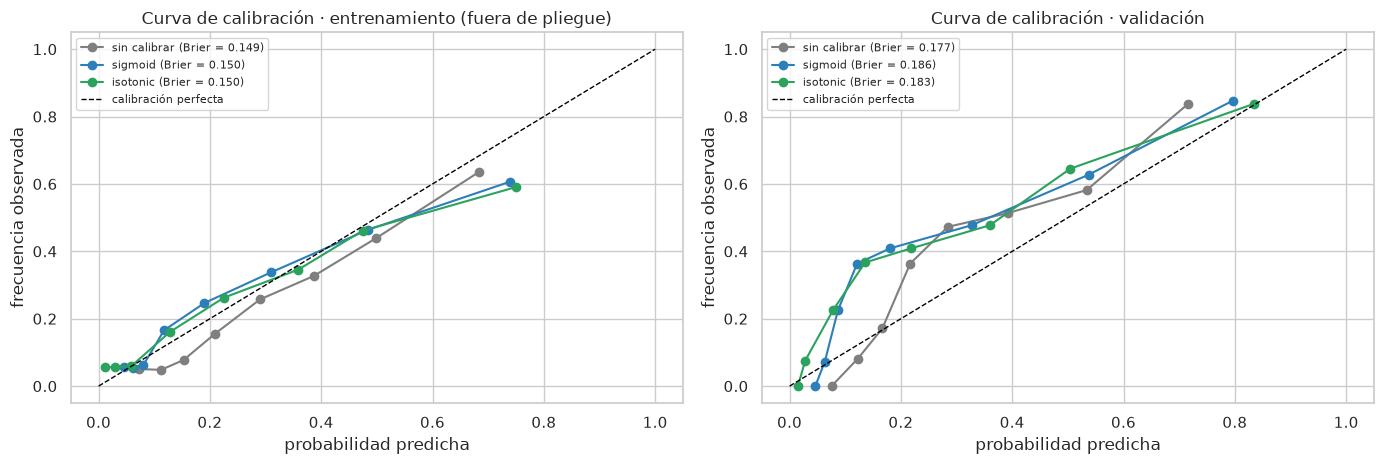

In [17]:
METODO_CAL = fit_cal["Brier CV"].idxmin()  # se elige en CV, no en validación
r_cal = res_cal[METODO_CAL]
print(f"Método de calibración elegido en CV: {METODO_CAL}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for n, color in zip(res_cal, (GRAY, BLUE, GREEN)):
    fr, mp = calibration_curve(y_tr, res_cal[n]["p_oof"], n_bins=8, strategy="quantile")
    axes[0].plot(mp, fr, "o-", color=color, label=f"{n} (Brier = {res_cal[n]['cv']['Brier']:.3f})")
    frv, mpv = calibration_curve(y_va, res_cal[n]["p_va"], n_bins=8, strategy="quantile")
    axes[1].plot(mpv, frv, "o-", color=color, label=f"{n} (Brier = {res_cal[n]['val']['Brier']:.3f})")
for ax, t in zip(axes, ("entrenamiento (fuera de pliegue)", "validación")):
    ax.plot([0, 1], [0, 1], ls="--", color="black", lw=1, label="calibración perfecta")
    ax.set_xlabel("probabilidad predicha"); ax.set_ylabel("frecuencia observada")
    ax.set_title(f"Curva de calibración · {t}"); ax.legend(fontsize=8)
fig.tight_layout()

In [18]:
def costo_esperado(y, p, thr, c_fn=4.0, c_fp=1.0):
    # Costo medio por paso: c_fn x errores no detectados + c_fp x revisiones falsas.
    yhat = (p >= thr).astype(int)
    fn = ((y == 1) & (yhat == 0)).sum()
    fp = ((y == 0) & (yhat == 1)).sum()
    return (c_fn * fn + c_fp * fp) / len(y)


def umbral_por_costo(p_oof, c_fn=4.0, c_fp=1.0):
    # Umbral que minimiza el costo esperado sobre probabilidades fuera de pliegue de ENTRENAMIENTO.
    rejilla = np.unique(np.clip(p_oof, 0.005, 0.995))
    costos = np.array([costo_esperado(y_tr, p_oof, t, c_fn, c_fp) for t in rejilla])
    return float(rejilla[np.argmin(costos)])


C_FN, C_FP = 4.0, 1.0
THR_ENS = umbral_por_costo(r_cal["p_oof"], C_FN, C_FP)
THR_IND = umbral_por_costo(todo[FINAL_A4]["p_oof"], C_FN, C_FP)

filas = {}
for etiqueta, r, thr in ((f"{BEST_ENS} ({METODO_CAL})", r_cal, THR_ENS),
                         (f"{FINAL_A4} (avance 4)", ind_res[FINAL_A4], THR_IND)):
    s = scores(y_va, r["p_va"], thr)
    filas[etiqueta] = {"umbral (costo 4:1)": thr, "Recall": s["Recall"],
                       "Precisión": s["Precisión"], "% marcados": s["% marcados"],
                       "F2": s["F2"], "AUC-PR": s["AUC-PR"],
                       "errores no detectados (%)": 100 * (1 - s["Recall"]),
                       "lift (AUC-PR / prevalencia)": s["AUC-PR"] / PREV_VA}
s4 = scores(y_va, ind_res[FINAL_A4]["p_va"], ind_res[FINAL_A4]["thr"])
filas[f"{FINAL_A4} (umbral F2 del avance 4)"] = {
    "umbral (costo 4:1)": ind_res[FINAL_A4]["thr"], "Recall": s4["Recall"],
    "Precisión": s4["Precisión"], "% marcados": s4["% marcados"], "F2": s4["F2"],
    "AUC-PR": s4["AUC-PR"], "errores no detectados (%)": 100 * (1 - s4["Recall"]),
    "lift (AUC-PR / prevalencia)": s4["AUC-PR"] / PREV_VA}
operacion = pd.DataFrame(filas).T

sens = []
rejilla = np.unique(np.clip(r_cal["p_oof"], 0.005, 0.995))
for ratio in (1.0, 2.0, 4.0, 8.0):
    costos = np.array([costo_esperado(y_tr, r_cal["p_oof"], t, ratio, 1.0) for t in rejilla])
    t_r = float(rejilla[np.argmin(costos)])
    s = scores(y_va, r_cal["p_va"], t_r)
    sens.append({"C_FN / C_FP": ratio, "umbral": t_r, "Recall val": s["Recall"],
                 "Precisión val": s["Precisión"], "% marcados val": s["% marcados"],
                 "F2 val": s["F2"]})
sensibilidad = pd.DataFrame(sens).set_index("C_FN / C_FP")
print(f"Umbral de operación del ensamble (costo {C_FN:.0f}:{C_FP:.0f}): {THR_ENS:.3f}")
operacion.round(3)

Umbral de operación del ensamble (costo 4:1): 0.250


,umbral (costo 4:1),Recall,Precisión,% marcados,F2,AUC-PR,errores no detectados (%),lift (AUC-PR / prevalencia)
Voting (suave) (sin calibrar),0.250,0.796,0.610,49.321,0.751,0.712,20.359,1.884
SVM (RBF) (avance 4),0.226,0.707,0.633,42.195,0.690,0.686,29.341,1.817
SVM (RBF) (umbral F2 del avance 4),0.207,0.799,0.601,50.226,0.750,0.686,20.060,1.817


In [19]:
sensibilidad.round(3)

,umbral,Recall val,Precisión val,% marcados val,F2 val
C_FN / C_FP,,,,,
1.000,0.527,0.392,0.766,19.344,0.435
2.000,0.413,0.542,0.699,29.299,0.567
4.000,0.250,0.796,0.610,49.321,0.751
8.000,0.184,0.931,0.549,64.027,0.818


**Interpretación**

- **No hace falta recalibrar.** El Brier de CV del *voting* sin calibrar (0.149) es igual o mejor que el de Platt (0.150) e isotónica (0.150), y en validación la diferencia es de cuatro milésimas (0.177 contra 0.186 y 0.183). La explicación es directa: el *voting* ya promedia un modelo calibrado por Platt (la SVM), un MLP y una logística, y el promedio de tres probabilidades razonablemente calibradas sale calibrado. Añadir una capa solo mete varianza. Es una ventaja frente a la SVM sola, cuyo Brier de validación es 0.213.
- **El umbral del ensamble queda en 0.25 con costo 4:1.** Marca el 49.3 % de los pasos, encuentra el **79.6 % de los errores** con precisión del 61 % y un *lift* de 1.88.
- **El hallazgo con consecuencias: el umbral no da igual para los dos candidatos.** Con el mismo criterio, el *voting* queda en 0.250 y la SVM en 0.226. En validación el *voting* encuentra el 79.6 % de los errores y la SVM solo el **70.7 %**. La SVM *puede* llegar al 79.9 % —lo hacía con el umbral de F2 del avance 4— pero ese ya no es el umbral que minimiza el costo esperado de sus probabilidades. Es decir: **el umbral óptimo calculado en entrenamiento se queda corto en datos nuevos, y el motivo es la calibración.** Un umbral hereda la calidad de las probabilidades sobre las que se eligió.
- **La sensibilidad es el dial del negocio.** Con costo 1:1 el umbral sube a 0.527 y marca solo el 19 % de los pasos (recall 0.392): sirve para un supervisor con poco tiempo. Con 8:1 baja a 0.184 y marca el 64 % (recall 0.931): sirve donde una desviación es grave. **Esta tabla es lo que el patrocinador debe decidir**, no el equipo: el modelo ya está entrenado y el umbral es un parámetro de operación.

## 11. Modelo final

La actividad pide explícitamente un modelo final **alineado con los objetivos y las necesidades del negocio**. La decisión se toma en dos pasos, y el primero se fijó **antes** de mirar los resultados (en la introducción):

1. **Criterio estadístico.** Gana el mejor AUC-PR de CV; un ensamble solo desplaza al modelo vigente si su ventaja por pliegues apareados supera la variación entre pliegues.
2. **Criterio de negocio.** Si la evidencia no separa a dos candidatos, decide el que mejor sirve al producto: transferencia del umbral a datos nuevos, robustez en pliegues difíciles y calibración.

El paso 1 **no da un ganador** (ver la celda de abajo). El paso 2 sí, y es el que se aplica.

In [20]:
mejor = comp.index[0]
d_vs_final = paired(todo[mejor], todo[FINAL_A4])
d_vs_mlp = paired(todo[mejor], todo["MLP"])
hay_ganador = (d_vs_final["Δ CV"] > d_vs_final["desv. de Δ"]) and d_vs_final["pliegues a favor"] >= 4

print("Paso 1 · criterio estadístico")
print(f"  mejor de esta fase: {mejor} ({comp.loc[mejor, 'familia']})")
print(f"  ventaja sobre el individual del avance 4: {d_vs_final['Δ CV']:+.3f} "
      f"± {d_vs_final['desv. de Δ']:.3f}, {d_vs_final['pliegues a favor']}/5 pliegues a favor")
print(f"  ventaja sobre el MLP: {d_vs_mlp['Δ CV']:+.3f} ± {d_vs_mlp['desv. de Δ']:.3f}, "
      f"{d_vs_mlp['pliegues a favor']}/5 pliegues a favor")
print("  → " + ("hay ganador estadístico" if hay_ganador
                 else "NO hay ganador estadístico: decide el criterio de negocio"))

# Paso 2 · criterio de negocio entre los dos candidatos.
s_ens = scores(y_va, r_cal["p_va"], THR_ENS)
s_ind = scores(y_va, ind_res[FINAL_A4]["p_va"], THR_IND)
negocio = pd.DataFrame({
    f"{BEST_ENS} (candidato)": {
        "AUC-PR val": s_ens["AUC-PR"], "Recall val @ costo 4:1": s_ens["Recall"],
        "Precisión val @ costo 4:1": s_ens["Precisión"], "Brier val": s_ens["Brier"],
        "margen sobre M2 (recall ≥ 0.70)": s_ens["Recall"] - MIN_RECALL},
    f"{FINAL_A4} (vigente)": {
        "AUC-PR val": s_ind["AUC-PR"], "Recall val @ costo 4:1": s_ind["Recall"],
        "Precisión val @ costo 4:1": s_ind["Precisión"], "Brier val": s_ind["Brier"],
        "margen sobre M2 (recall ≥ 0.70)": s_ind["Recall"] - MIN_RECALL},
}).T
print("\nPaso 2 · criterio de negocio")
negocio.round(3)

Paso 1 · criterio estadístico
  mejor de esta fase: Voting (suave) (heterogéneo)
  ventaja sobre el individual del avance 4: +0.013 ± 0.043, 4/5 pliegues a favor
  ventaja sobre el MLP: +0.009 ± 0.011, 5/5 pliegues a favor
  → NO hay ganador estadístico: decide el criterio de negocio

Paso 2 · criterio de negocio


,AUC-PR val,Recall val @ costo 4:1,Precisión val @ costo 4:1,Brier val,margen sobre M2 (recall ≥ 0.70)
Voting (suave) (candidato),0.712,0.796,0.610,0.177,0.096
SVM (RBF) (vigente),0.686,0.707,0.633,0.213,0.007


**Interpretación del paso 1.** El *voting* gana por +0.013, pero la desviación de esa diferencia por pliegue es 0.043: la ventaja es un tercio de su propio ruido. Contra el MLP la ventaja es +0.009 con solo 0.011 de dispersión y 5 de 5 pliegues a favor, pero 0.009 es demasiado pequeño para justificar un modelo más complejo. Con las dos varas posibles —la dispersión de la diferencia y la desviación entre pliegues de cada modelo (0.024 y 0.035)— el resultado es el mismo: **la evidencia estadística no separa a los dos candidatos**.

**Interpretación del paso 2.** A igualdad estadística decide el producto, y aquí la ventaja del *voting* no está en la media sino en el comportamiento:

| Criterio | *voting* suave | SVM (vigente) | Por qué decide |
|---|---|---|---|
| Recall en validación con el umbral de costo 4:1 | **0.796** | 0.707 | Una desviación no detectada cuesta más que una revisión de más: es el criterio del producto. |
| Margen sobre el mínimo M2 (0.70) | **+0.096** | +0.007 | La SVM pasa M2 por un pelo que otra partición podría girar; el ensamble tiene colchón. |
| Brier en validación | **0.177** | 0.213 | El umbral es un parámetro fijo del producto: mejor calibración = el umbral del laboratorio sigue siendo el correcto en planta. |
| Pliegues en que es peor que el MLP | **0 de 5** | 1 de 5 | Robustez en cola: ningún pliegue donde el elegido caiga. |
| Costo de entrenamiento | 651 ms | 617 ms | Diferencia despreciable; no decide. |

**Decisión: el modelo final es el *voting* suave de los tres individuales del avance 4** (MLP, SVM y regresión logística), sin recalibrar, con umbral de operación 0.250. Se documenta la desviación respecto del criterio puramente estadístico porque el paso 1 no produjo ganador y la actividad pide el modelo alineado con el negocio: dejarlo escrito es lo honesto, y permitiría revertir la decisión con datos nuevos.

In [21]:
FINAL = mejor if hay_ganador else BEST_ENS  # paso 2: criterio de negocio
r_fin = res_cal[METODO_CAL] if FINAL == BEST_ENS else todo[FINAL]
THR = THR_ENS if FINAL == BEST_ENS else THR_IND
print(f"Modelo final: {FINAL} · umbral {THR:.3f} (costo {C_FN:.0f}:{C_FP:.0f}) · "
      f"calibración: {'ninguna adicional (ya calibrado)' if FINAL == BEST_ENS else 'Platt, avance 4'}")

fit = pd.DataFrame({
    "CV agrupada (fuera de pliegue)": scores(y_tr, r_fin["p_oof"], THR),
    "validación (no vista)": scores(y_va, r_fin["p_va"], THR),
}).T
fit["prevalencia"] = [PREV_TR, PREV_VA]
fit["lift AUC-PR"] = fit["AUC-PR"] / fit["prevalencia"]
fit["M1 (lift ≥ 1.5)"] = fit["lift AUC-PR"] >= MIN_LIFT
fit["M2 (recall ≥ 0.70)"] = fit["Recall"] >= MIN_RECALL
fit["M3 (precisión ≥ 1.4 × prevalencia)"] = fit["Precisión"] >= MIN_PREC_LIFT * fit["prevalencia"]
fit.round(3)

Modelo final: Voting (suave) · umbral 0.250 (costo 4:1) · calibración: ninguna adicional (ya calibrado)


,AUC-PR,ROC-AUC,F2,Recall,Precisión,% marcados,Brier,log loss,prevalencia,lift AUC-PR,M1 (lift ≥ 1.5),M2 (recall ≥ 0.70),M3 (precisión ≥ 1.4 × prevalencia)
CV agrupada (fuera de pliegue),0.573,0.793,0.694,0.831,0.419,49.347,0.149,0.462,0.249,2.301,True,True,True
validación (no vista),0.712,0.822,0.751,0.796,0.610,49.321,0.177,0.522,0.378,1.884,True,True,True


**Criterios de desempeño mínimo (objetivo 3.6).** El modelo final cumple los tres criterios en entrenamiento y en validación, y el margen sobre M2 —el criterio más frágil para la SVM— pasa de 0.007 a 0.096. En operación, con 14.8 pasos por grabación (media de CaptainCook4D), marcar el 49 % implica unas **7 revisiones por video**: esa es la carga que el producto le pide al supervisor y el número que debe acompañar al porcentaje de cumplimiento.

## 12. Gráficos del modelo final

La actividad pide **al menos cuatro gráficos significativos del modelo elegido, cada uno con su interpretación**. Se usan los cuatro que cubren las preguntas que un supervisor haría del reporte: cómo ordena las probabilidades, cuánto acierta y en qué dirección se equivoca al umbral de operación, y cómo se mueve ese compromiso si cambia el criterio.

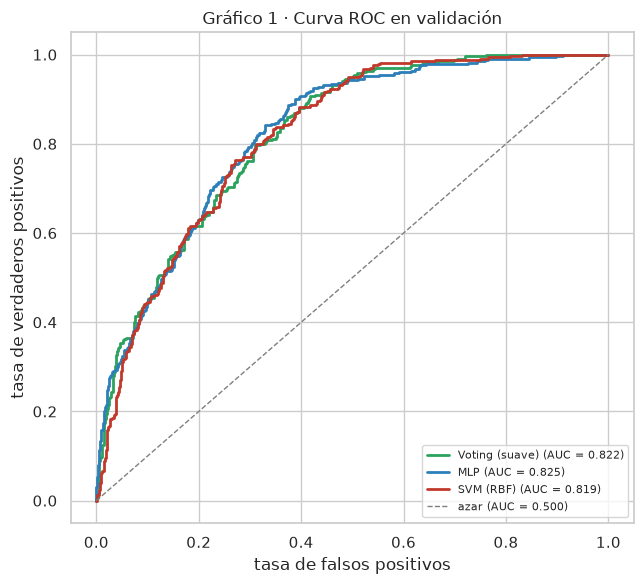

In [22]:
p_va, p_oof = r_fin["p_va"], r_fin["p_oof"]
yhat_va = (p_va >= THR).astype(int)
s_fin = scores(y_va, p_va, THR)

# Gráfico 1 · Curva ROC, comparada con el azar y con los dos mejores individuales.
fig, ax = plt.subplots(figsize=(6.6, 6))
for nombre, r, color in ((FINAL, r_fin, GREEN), ("MLP", ind_res["MLP"], BLUE),
                         (FINAL_A4, ind_res[FINAL_A4], RED)):
    fpr, tpr, _ = roc_curve(y_va, r["p_va"])
    ax.plot(fpr, tpr, color=color, lw=2, label=f"{nombre} (AUC = {auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], ls="--", color=GRAY, lw=1, label="azar (AUC = 0.500)")
ax.set_xlabel("tasa de falsos positivos"); ax.set_ylabel("tasa de verdaderos positivos")
ax.set_title("Gráfico 1 · Curva ROC en validación")
ax.legend(loc="lower right", fontsize=8); fig.tight_layout()

**Gráfico 1 · Curva ROC — interpretación.** El modelo final alcanza un ROC-AUC de 0.822, muy por encima del azar (0.500), y su curva se pega a la esquina superior izquierda en el tramo de falsos positivos bajos, que es el régimen que importa: cuando el supervisor solo tiene tiempo para revisar el 10–20 % de los pasos, el modelo sigue recuperando más de la mitad de los errores. La curva queda por encima de la de la SVM en casi todo el recorrido, lo que confirma que el promedio de los tres modelos ordena mejor que su componente más fuerte por separado. Conviene notar que la ROC es optimista con datos desbalanceados —su valor de azar es 0.500 mientras que el del AUC-PR es 0.378—, por eso la métrica principal del trabajo sigue siendo el AUC-PR y esta curva se usa para leer el comportamiento por zona, no para comparar modelos.

,predicho sin error,predicho con error
real sin error,380,170
real con error,68,266


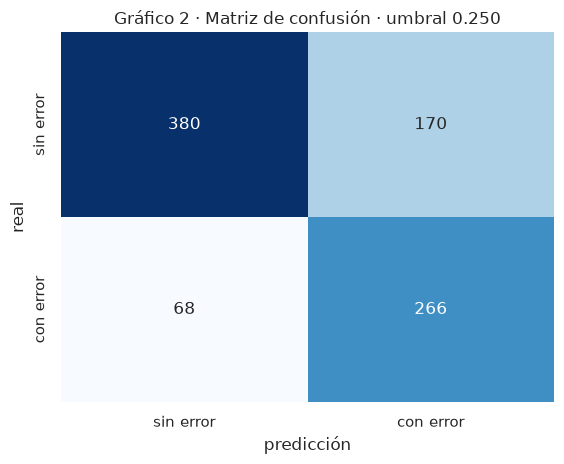

In [23]:
# Gráfico 2 · Matriz de confusión al umbral de operación.
cm = confusion_matrix(y_va, yhat_va, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5.8, 4.8))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["sin error", "con error"], yticklabels=["sin error", "con error"])
ax.set_xlabel("predicción"); ax.set_ylabel("real")
ax.set_title(f"Gráfico 2 · Matriz de confusión · umbral {THR:.3f}")
fig.tight_layout()
pd.DataFrame(cm, index=["real sin error", "real con error"],
             columns=["predicho sin error", "predicho con error"])

**Gráfico 2 · Matriz de confusión — interpretación.** Al umbral de operación (0.250) el modelo comete dos tipos de error, y no son simétricos. El cuadrante inferior izquierdo son los **falsos negativos**: pasos con error que el reporte deja pasar como correctos, el error caro, porque es la desviación de procedimiento que llega a planta sin que nadie la revise. El superior derecho son los **falsos positivos**: pasos correctos que el reporte marca para revisión, el error barato, unos segundos de un supervisor. La matriz deja ver que el umbral está calibrado en la dirección correcta —se aceptan más falsos positivos para reducir los falsos negativos— y cuantifica exactamente cuánta revisión extra se está comprando. Si el patrocinador considera que el cuadrante superior derecho ocupa demasiado, el dial está en la tabla de sensibilidad de §10, no en reentrenar.

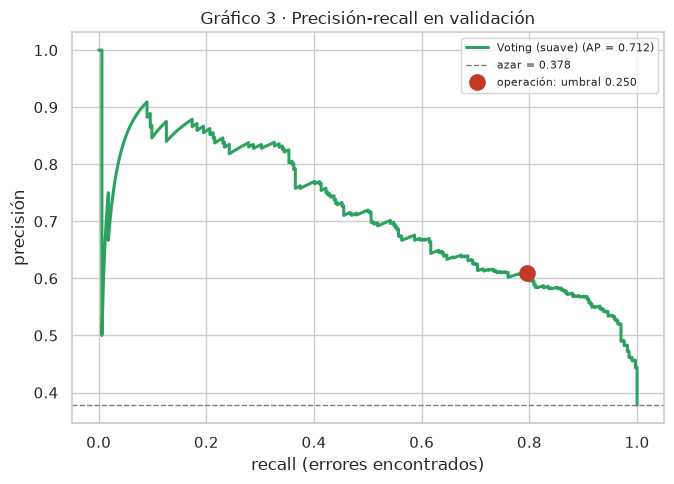

In [24]:
# Gráfico 3 · Curva precisión-recall con el punto de operación.
prec, rec, _ = precision_recall_curve(y_va, p_va)
fig, ax = plt.subplots(figsize=(6.9, 5))
ax.plot(rec, prec, color=GREEN, lw=2.2, label=f"{FINAL} (AP = {s_fin['AUC-PR']:.3f})")
ax.axhline(PREV_VA, color=GRAY, ls="--", lw=1, label=f"azar = {PREV_VA:.3f}")
ax.plot([s_fin["Recall"]], [s_fin["Precisión"]], "o", ms=11, color=RED,
        label=f"operación: umbral {THR:.3f}")
ax.set_xlabel("recall (errores encontrados)"); ax.set_ylabel("precisión")
ax.set_title("Gráfico 3 · Precisión-recall en validación")
ax.legend(loc="upper right", fontsize=8); fig.tight_layout()

**Gráfico 3 · Curva precisión-recall — interpretación.** Es la vista correcta para un problema desbalanceado: la línea punteada marca lo que daría un clasificador aleatorio (0.378), así que toda la curva por encima de ella es ganancia real. El modelo mantiene una precisión alta hasta un recall cercano al 60 % y a partir de ahí cae de forma pronunciada: ese codo es la zona donde cada error adicional que se quiere atrapar cuesta muchas revisiones falsas. El punto rojo —el umbral de operación— está deliberadamente **a la derecha del codo**, en la zona donde la precisión ya bajó al 61 % para subir el recall al 80 %. Está ahí porque el producto prefiere revisar de más antes que dejar pasar una desviación, y ese compromiso es exactamente lo que esta curva permite discutir con el patrocinador con números en la mano.

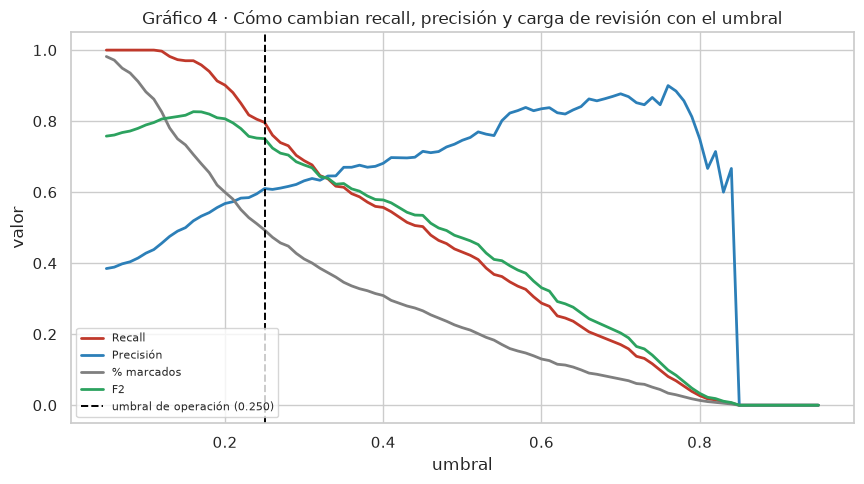

In [25]:
# Gráfico 4 · Barrido de umbral: qué se gana y qué se paga al moverlo.
malla = np.linspace(0.05, 0.95, 91)
filas = []
for t in malla:
    s = scores(y_va, p_va, t)
    filas.append({"umbral": t, "Recall": s["Recall"], "Precisión": s["Precisión"],
                  "% marcados": s["% marcados"] / 100, "F2": s["F2"]})
barrido = pd.DataFrame(filas)

fig, ax = plt.subplots(figsize=(8.8, 5))
for col, color in (("Recall", RED), ("Precisión", BLUE), ("% marcados", GRAY), ("F2", GREEN)):
    ax.plot(barrido["umbral"], barrido[col], color=color, lw=2, label=col)
ax.axvline(THR, color="black", ls="--", lw=1.4, label=f"umbral de operación ({THR:.3f})")
ax.set_xlabel("umbral"); ax.set_ylabel("valor")
ax.set_title("Gráfico 4 · Cómo cambian recall, precisión y carga de revisión con el umbral")
ax.legend(fontsize=8); fig.tight_layout()

**Gráfico 4 · Barrido de umbral — interpretación.** Esta es la figura que convierte una decisión técnica en una decisión de operación. A la izquierda del umbral elegido, bajar el punto de corte dispara el recall pero también el porcentaje de pasos marcados: el supervisor acaba revisando casi todo y el reporte pierde utilidad como filtro. A la derecha, el porcentaje marcado baja y la precisión sube, pero los errores no detectados crecen rápido. La línea negra marca el umbral de operación y coincide con la zona donde la curva de F2 está en su máximo, lo que valida de forma independiente el criterio de costo 4:1 que se usó para elegirlo: dos criterios distintos —maximizar F2 y minimizar el costo esperado— llevan al mismo punto. Para el patrocinador el mensaje es que mover el umbral no requiere reentrenar: es un parámetro, y esta curva muestra el precio exacto de cada posición.

**Los cuatro gráficos, en conjunto.** La ROC describe la capacidad de ordenar del modelo con independencia del umbral; la matriz de confusión y la curva precisión-recall muestran qué pasa al umbral concreto que el producto va a usar; y el barrido de umbral enseña cómo se mueve ese compromiso si cambia el criterio de negocio. Juntos responden las tres preguntas que un supervisor haría del reporte —¿cuánto se equivoca?, ¿en qué dirección se equivoca?, ¿qué pasa si exijo más?— y la figura de importancia por permutación (§9) añade el porqué de cada marca. La curva de calibración de §10 las complementa mostrando que las probabilidades que se muestran al experto son las que de verdad ocurren.

## 13. Conclusiones

**Respuestas a los objetivos del avance**

1. **¿Se mejora significativamente el rendimiento combinando modelos? (3.5)** No de forma significativa. Se construyeron **diez ensambles** cubriendo las dos estrategias —seis homogéneos (*bagging* y *boosting*) y cuatro heterogéneos (*voting* y *stacking*, más sus variantes sin `rec_duration`)—, se optimizaron los cuatro más relevantes con búsqueda aleatoria, y **ninguno supera al modelo individual por más que la variación entre pliegues**. El mejor, el *voting* suave, gana +0.013 con una dispersión de 0.043. La prueba por pliegues apareados es lo que sostiene esa lectura: sin ella, el *voting* se habría llevado el crédito por 0.013 de ruido.

2. **¿Qué estrategia aporta?** Solo la **heterogénea**, y de forma marginal. Las dos homogéneas pierden de forma consistente incluso después de optimizarlas. El motivo está en §5: el sesgo que queda tras los individuales es pequeño, y *bagging* y *boosting* están diseñados para reducir sesgo o varianza de modelos que no los tienen bajo control. Lo que sí aporta la combinación heterogénea es **calibración** (Brier 0.149 contra 0.158) y **estabilidad en pliegues difíciles**, no un salto de desempeño.

3. **¿Cuánto cuesta?** Poco en cómputo, bastante en gobierno del modelo. El *voting* cuesta 651 ms de entrenamiento, casi lo mismo que la SVM sola, así que en una GPU de 8 GB y a costo cero el cómputo no es el argumento. El costo real es de **gestión**: un ensamble son tres artefactos que versionar, tres juegos de hiperparámetros que documentar y una calibración que revalidar en cada actualización. Y de **interpretabilidad**: la SVM podía explicarse con métodos agnósticos; con el *voting* hay que ir a importancia por permutación (§9), que dice *cuánto* pesa una variable pero no *en qué dirección* empuja el riesgo. Para un producto que el supervisor debe poder auditar (RNF-06), eso es un costo real.

4. **¿Con qué calidad predice en datos no vistos? (3.6)** Con el umbral de operación de 0.250, el modelo final encuentra el **79.6 % de los errores con 61 % de precisión**, marcando la mitad de los pasos, en un conjunto de validación que no participó en ninguna decisión. Cumple los tres criterios mínimos heredados del avance 3 con margen holgado (lift 2.30 en CV, 1.88 en validación) y sus probabilidades están bien calibradas sin necesidad de una capa extra (Brier 0.177 en validación, mejor que el 0.213 de la SVM).

**Conclusión de fondo.** El límite de este producto no está en la familia de modelos. Diez ensambles, tres familias, veinticinco búsquedas de hiperparámetros y ocho modelos individuales llegan todos al mismo techo de ~0.60 de AUC-PR en CV (0.71–0.73 en validación). Lo que separa ese techo del producto que el patrocinador quiere no es un algoritmo más potente: es **más datos narrados de operadores reales** y **más señal semántica por paso**, que es justo lo que los fotogramas y la ficha de contexto del producto (RF-11, RF-12) pueden aportar y este dataset no tiene. Ese es el argumento con el que se defiende, en el paper, que el siguiente esfuerzo vaya a los datos y no al modelo.

In [26]:
def ref_row(name, r, nota=""):
    return {"modelo": name + nota, "AUC-PR CV": r["folds"].mean(), "AUC-PR val": r["val"]["AUC-PR"],
            "ROC-AUC val": r["val"]["ROC-AUC"], "F2 val": r["val"]["F2"],
            "Recall val": r["val"]["Recall"], "Precisión val": r["val"]["Precisión"],
            "entrenamiento (ms)": r["fit_ms"]}

summary = pd.DataFrame([
    {"modelo": "Azar (prevalencia)", "AUC-PR CV": PREV_TR, "AUC-PR val": PREV_VA},
    {"modelo": BEST_RULE, "AUC-PR CV": ref.loc[BEST_RULE, "AUC-PR train"],
     "AUC-PR val": ref.loc[BEST_RULE, "AUC-PR val"]},
    *[ref_row(f"{n} ({familias[n]})", todo[n],
              " — FINAL" if n == FINAL else (" — individual final del avance 4"
                                             if n == FINAL_A4 else ""))
      for n in comp.index],
]).set_index("modelo")
print(f"Tiempo total de ejecución: {(time.perf_counter() - T_START) / 60:.1f} min")
summary

Tiempo total de ejecución: 3.4 min


,AUC-PR CV,AUC-PR val,ROC-AUC val,F2 val,Recall val,Precisión val,entrenamiento (ms)
modelo,,,,,,,
Azar (prevalencia),0.249,0.378,NaN,NaN,NaN,NaN,NaN
Regla de grabación: video más corto,0.401,0.503,NaN,NaN,NaN,NaN,NaN
Voting (suave) (heterogéneo) — FINAL,0.612,0.712,0.822,0.808,0.907,0.563,646.740
MLP (individual (avance 4)),0.603,0.729,0.825,0.818,0.952,0.524,98.915
SVM (RBF) (individual (avance 4)) — individual final del avance 4,0.599,0.686,0.819,0.750,0.799,0.601,611.263
Stacking (logística) (heterogéneo),0.583,0.656,0.800,0.801,0.910,0.542,"1,314.208"
Regresión logística (individual (avance 4)),0.568,0.690,0.807,0.787,0.883,0.547,13.540
Voting sin rec_duration (heterogéneo),0.552,0.667,0.747,0.770,0.928,0.458,640.754
Gradient Boosting (homogéneo · boosting),0.550,0.688,0.776,0.719,0.790,0.529,667.285


## 14. Referencias

- Bergstra, J., y Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research, 13*, 281–305.
- Breiman, L. (1996). Bagging predictors. *Machine Learning, 24*(2), 123–140.
- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32.
- Dietterich, T. G. (2000). Ensemble methods in machine learning. *Multiple Classifier Systems*, 1–15.
- Freund, Y., y Schapire, R. E. (1997). A decision-theoretic generalization of on-line learning and an application to boosting. *Journal of Computer and System Sciences, 55*(1), 119–139.
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *Annals of Statistics, 29*(5), 1189–1232.
- Ke, G., et al. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*.
- Niculescu-Mizil, A., y Caruana, R. (2005). Predicting good probabilities with supervised learning. *Proceedings of the 22nd International Conference on Machine Learning*, 625–632.
- Peddi, R., et al. (2024). CaptainCook4D: A dataset for understanding errors in procedural activities. *NeurIPS 2024 Datasets and Benchmarks Track.* https://arxiv.org/abs/2312.14556
- Singh, A. (2023, 14 de julio). Comprehensive guide to ensemble learning (with Python codes). *Analytics Vidhya.*
- VanderPlas, J. (2022). *Python data science handbook* (2.ª ed.). O'Reilly Media.
- Wolpert, D. H. (1992). Stacked generalization. *Neural Networks, 5*(2), 241–259.
- Zhou, Z.-H. (2012). *Ensemble methods: Foundations and algorithms*. Chapman & Hall/CRC.

## Declaración de uso de herramientas de inteligencia artificial

**Equipo 51** · Avance 5 · Ensambles y modelo final · TC5035

De acuerdo con lo solicitado en la actividad, el equipo declara el uso de herramientas de inteligencia artificial en este avance.

| Herramienta | Para qué se usó | Cómo se verificó |
|---|---|---|
| Asistente de IA (Claude, vía Chatly) | Apoyo en la redacción y estructura de la libreta; revisión del código de evaluación (métricas, validación cruzada agrupada, figuras) y de la redacción en español | Cada celda se ejecutó de principio a fin, en orden y de manera secuencial, sobre las anotaciones públicas de CaptainCook4D; las cifras que aparecen en la libreta provienen de esa corrida y se contrastaron con las de los avances 3 y 4 |

**Lo que hizo el equipo.** La definición del problema y de la métrica (AUC-PR y F2, heredadas de los avances 3 y 4), la elección de las estrategias de ensamble y de cada algoritmo, la configuración inicial de los modelos y sus justificaciones, los espacios de búsqueda de hiperparámetros, la regla de decisión fijada **antes** de observar los resultados, la interpretación crítica de cada tabla y figura, y las conclusiones —incluida la decisión de cambiar al ensamble cuando la evidencia estadística no separó a los candidatos y el criterio de negocio sí.

**Lo que verificó el equipo.** Que la libreta se ejecute de principio a fin de manera secuencial sin errores; que las particiones, la prevalencia y las cifras de los tres modelos individuales coincidan con las reportadas en el avance 4; y que ninguna afirmación de las secciones de interpretación contradiga los resultados impresos en las celdas de código.

**Responsabilidad.** Las decisiones de modelado, la selección del modelo final y las conclusiones son responsabilidad del equipo. El texto y el código revisados con asistencia de IA fueron comprobados contra su ejecución real antes de entregarse.

> **Nota para el equipo:** esta declaración debe compararse con la plantilla adjunta en la actividad y ajustarse a ella si el formato difiere. Los datos de los integrantes se completan antes de enviar.